## Can Dimensional Analysis Make Machine Learning Models Extrapolate?

#### Nakul Sanadhya
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering, The University of Texas at Austin

### Subsurface Machine Learning Course, The University of Texas at Austin
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering
#### Department of Geological Sciences, Jackson School of Geosciences

_____________________

Workflow supervision and review by:

#### Instructor: Prof. Michael Pyrcz, Ph.D., P.Eng., Professor, The University of Texas at Austin
[Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Geostatistics Book](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) | [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)  | [Applied Geostats in Python e-book](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)

#### Course TA: Alexander Ifenaike, Graduate Student, The University of Texas at Austin

### Executive Summary

When a water-saturated column of soil or rock is loaded, it compresses at once and then keeps settling as water drains out; machine-learning models trained on simulations of this consolidation are often used outside the range of their training data, where it is not obvious whether the model or the representation of its inputs and target matters more. I used 2,900 simulations of a three-layer column, 2,000 for training and 900 for evaluation, to train linear regression, a random forest and a neural network on three versions of the same data (raw values, their logarithms, and dimensionless groups from the governing equations), and tested them in range, on larger columns and loads, and on a fluid-solid coupling outside its training range. With dimensionless inputs and target the neural network had the lowest errors on all four evaluation sets, similar in range and on the larger scales (95th-percentile worst error 3.6% and 3.2% of the delayed settlement, against 52-362% for raw and log inputs) and about 6-16% on the coupling shift, while cross-validation that mixed rows of the same simulation underestimated the held-out test error by about a factor of five. In these comparisons the dimensionless representation improved performance far more than the choice of model, so I recommend dimensionless inputs and target when the governing equations are known, checking where new cases fall relative to the training data, and validation folds grouped by simulation.

### Import Packages

In [1]:
import sys                                    # Python version
import warnings                               # MLP warnings during CV only
import numpy as np                            # arrays, percentiles
import pandas as pd                           # CSV files, results table
import matplotlib as mpl                      # version
import matplotlib.pyplot as plt               # figures
import sklearn                                # version
from joblib import parallel_config            # threads per CV worker
from matplotlib.patches import Rectangle      # schematic, training box
from matplotlib.ticker import NullFormatter   # plain log-axis ticks
from sklearn.compose import TransformedTargetRegressor  # scaled target
from sklearn.ensemble import RandomForestRegressor      # tree ensemble
from sklearn.exceptions import ConvergenceWarning       # warning silenced
from sklearn.linear_model import LinearRegression       # linear model
from sklearn.model_selection import GroupKFold, KFold   # CV folds
from sklearn.model_selection import cross_val_predict   # out-of-fold
from sklearn.neural_network import MLPRegressor         # neural network
from sklearn.pipeline import make_pipeline              # scaler + model
from sklearn.preprocessing import StandardScaler        # standardize
from threadpoolctl import threadpool_limits             # cap threads
%config InlineBackend.figure_formats = ['svg']
print(f"Python {sys.version.split()[0]}, numpy {np.__version__}, "
      f"pandas {pd.__version__}, scikit-learn {sklearn.__version__}, "
      f"matplotlib {mpl.__version__}")

Python 3.12.7, numpy 1.26.4, pandas 2.2.2, scikit-learn 1.7.1, matplotlib 3.9.2


### Functions

The following functions will be used in the workflow.

* `physics`: closed-form undrained and drained settlements and series-averaged properties of each column
* `represent`: one of the three input representations, one row per (simulation, time)

In [2]:
MU, N_T, SEED = 1e-3, 41, 0         # water viscosity [Pa s], times, seed
N_JOBS, CV_JOBS = 8, 3              # threads; CV folds run in parallel
TIMES = [f"t_{i:02d}" for i in range(N_T)]
SETTLE = [f"s_{i:02d}" for i in range(N_T)]
INPUTS = ["H_m", "sigma0_Pa", "M_Pa", "alpha", "k1_m2", "k2_m2", "k3_m2",
          "Mc1_Pa", "Mc2_Pa", "Mc3_Pa"]
KINDS = ["raw", "log", "dimensionless"]

def physics(df):
    """Closed-form limits and series-averaged properties (3 equal layers)."""
    H, sig, M, a = (df[c].to_numpy() for c in INPUTS[:4])
    k, Mc = df[INPUTS[4:7]].to_numpy(), df[INPUTS[7:]].to_numpy()
    Mc_eff, k_eff = 3 / (1 / Mc).sum(1), 3 / (1 / k).sum(1)
    cv = k / MU / (1 / M[:, None] + a[:, None] ** 2 / Mc)     # [m2/s]
    cv_eff = k_eff / MU / (1 / M + a ** 2 / Mc_eff)
    Mu = Mc + a[:, None] ** 2 * M[:, None]                   # undrained
    return dict(H=H, alpha=a, Mc=Mc, Mc_eff=Mc_eff, cv=cv, cv_eff=cv_eff,
                s0=sig * H / 3 * (1 / Mu).sum(1),            # [m]
                s_inf=sig * H / 3 * (1 / Mc).sum(1),         # [m]
                kappa=a ** 2 * M / Mc_eff)

def represent(df, kind):
    """X and y, one row per (simulation, time), and the map y -> s [m]."""
    p, t, s = physics(df), df[TIMES].to_numpy(), df[SETTLE].to_numpy()
    rep = lambda v: np.repeat(np.asarray(v), N_T)    # value on every time
    if kind == "raw":
        X = np.column_stack([rep(df[c]) for c in INPUTS] + [t.ravel()])
        return X, s.ravel(), lambda y: y
    if kind == "log":
        X = np.column_stack(
            [rep(df[c] if c == "alpha" else np.log10(df[c])) for c in INPUTS]
            + [np.log10(t).ravel()])
        return X, np.log10(s).ravel(), lambda y: 10 ** y
    Tv = t * p["cv_eff"][:, None] / p["H"][:, None] ** 2     # clock [-]
    X = np.column_stack(
        [np.log10(Tv).ravel()]
        + [rep(np.log10(p["cv"][:, j] / p["cv_eff"])) for j in range(3)]
        + [rep(np.log10(p["Mc"][:, j] / p["Mc_eff"])) for j in range(3)]
        + [rep(p["alpha"]), rep(np.log10(p["kappa"]))])
    s0, s_inf = rep(p["s0"]), rep(p["s_inf"])
    return X, (s.ravel() - s0) / (s_inf - s0), lambda y: s0 + y * (s_inf - s0)

* `worst_error`, `scores`: the metric and the physical checks (defined in Step 3)
* `make_model`, `cv_predict`: the three models and their out-of-fold predictions (each made by a model not trained on that simulation)

In [3]:
def worst_error(df, s_pred):
    """Worst error over time per run: / (s_inf - s0) and / s_inf."""
    p, s = physics(df), df[SETTLE].to_numpy()
    worst = np.abs(s_pred.reshape(s.shape) - s).max(1)
    return worst / (p["s_inf"] - p["s0"]), worst / p["s_inf"]

def scores(df, s_pred):
    """P95 over runs of the worst error [%]; % of runs failing a check."""
    p, sp = physics(df), s_pred.reshape(-1, N_T)
    primary, secondary = worst_error(df, s_pred)
    band = (p["s_inf"] - p["s0"])[:, None]
    falls = (np.diff(sp, axis=1) < -1e-3 * band).any(1)    # must not fall
    outside = ((sp < p["s0"][:, None] - 0.01 * band)
               | (sp > p["s_inf"][:, None] + 0.01 * band)).any(1)
    return {"P95": 100 * np.percentile(primary, 95),
            "P95 of s_inf": 100 * np.percentile(secondary, 95),
            "non-monotone": 100 * falls.mean(),
            "out of bounds": 100 * outside.mean()}

GRIDS = {"linear": [{}],
         "random forest": [{"min_samples_leaf": n} for n in (1, 5)],
         "MLP": [{"alpha": a, "tol": tol}
                 for a in (1e-4, 1e-2) for tol in (1e-4, 1e-5)]}

def make_model(name, n_jobs=N_JOBS, **hp):
    """Standardized inputs and target for every model."""
    if name == "linear":
        est = LinearRegression()
    elif name == "random forest":          # trees too: some versions treat
        est = RandomForestRegressor(      # spreads below 1e-7 as constant
            n_estimators=100, max_features=0.6, n_jobs=n_jobs,
            random_state=SEED, **hp)
    else:
        est = MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=500,
                           early_stopping=False, random_state=SEED, **hp)
    return TransformedTargetRegressor(make_pipeline(StandardScaler(), est),
                                      transformer=StandardScaler())

def cv_predict(name, hp, df, kind, cv):
    """Out-of-fold settlement [m]; 3 folds in parallel, 2 threads each."""
    X, y, to_s = represent(df, kind)
    groups = np.repeat(np.arange(len(df)), N_T)
    groups = groups if isinstance(cv, GroupKFold) else None
    with parallel_config(backend="loky", inner_max_num_threads=2):
        y_cv = cross_val_predict(make_model(name, n_jobs=2, **hp), X, y,
                                 groups=groups, cv=cv, n_jobs=CV_JOBS)
    return to_s(y_cv)

threadpool_limits(N_JOBS)                   # at most 8 threads in total

* figure colours and markers, and two labelling helpers

In [4]:
COLOR = {"raw": "#0072B2", "log": "#E69F00", "dimensionless": "#009E73"}
MODEL = {"linear": dict(marker="s", ls=":"),
         "random forest": dict(marker="^", ls="--"),
         "MLP": dict(marker="o", ls="-")}
BAND = dict(color="0.9", lw=0, zorder=0)               # training range
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8.5, "axes.titlesize": 9,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "0.35", "xtick.color": "0.35", "ytick.color": "0.35",
    "axes.grid": True, "grid.color": "0.92", "grid.linewidth": 0.6,
    "lines.linewidth": 1.4, "svg.fonttype": "path", "svg.hashsalt": "pge383",
    "savefig.dpi": 200})

def note(ax, x, y, text, box=False, **kw):
    """Direct label on a plot, optionally on a white box."""
    kw = dict(fontsize=7.5, ha="center", va="center") | kw
    if box:
        kw["bbox"] = dict(fc="white", ec="none", alpha=0.85, pad=1.2)
    ax.text(x, y, text, **kw)

def plain_log(axis, ticks, labels=None):
    """Log axis with chosen ticks and plain labels."""
    axis.set_ticks(ticks, labels or [f"{t:g}" for t in ticks])
    axis.set_minor_formatter(NullFormatter())

### Load Data

2,900 simulations of 1D consolidation of a column of three layers of equal thickness, numbered 1-3 from the top, from a layered finite-volume solver extended from the reference solver in [poroConsolidationFoam](https://github.com/nakulsanadhya/poroConsolidationFoam) (verified against the exact Terzaghi solution):
* at t = 0 a load σ0 is applied on top; the column compresses at once, then keeps settling as water drains out through the top
* one row per simulation: 10 inputs, then 41 log-spaced times `t_00`-`t_40` [s], from early settlement of the fastest layer to full drainage, and the settlements `s_00`-`s_40` [m]
* inputs: thickness **H** [m], load **σ0** [Pa], Biot modulus **M** [Pa] (fluid and pore compressibility), Biot coefficient **α** [-], and per layer the permeability **k1-k3** [m²] and drained constrained modulus **Mc1-Mc3** [Pa]
* splits: **train** (2000) and **test** (300) share the input ranges; the **scale shift** (`ood_scale`, 300) draws thickness, load and permeability from larger ranges but every dimensionless quantity from the same sampling distribution as train; the **coupling shift** (`ood_coupling`, 300) keeps every input in range except M, set so that κ lies 1-10x below (150) or above (150) its training range; its high side needs M up to 4e12 Pa, far beyond water-saturated rock, so it is a pure extrapolation test

| symbol | meaning |
|---|---|
| s0, s∞ | settlement immediately after loading, before water has drained, and final settlement once the excess pore pressure has dissipated [m]; both calculated directly from a formula |
| U | normalized settlement (s − s0)/(s∞ − s0), the share of the delayed settlement s∞ − s0 reached so far: 0 at loading, 1 when drained; e.g. s0 = 2 mm, s∞ = 10 mm and s = 6 mm give U = 0.5 |
| Tv | Tv = t/(H²/cv,eff), elapsed time relative to the column's characteristic consolidation time; cv = k/(μ(1/M + α²/Mc)) is the consolidation coefficient (μ: water viscosity) |
| κ | coupling group α²M/Mc,eff, the strength of the interaction between pore pressure and deformation of the solid skeleton; it sets the delayed share of settlement, κ/(1 + κ) in a uniform column |
| eff | column values: k_eff and Mc,eff are harmonic means of the layer values (layers in series), and cv,eff is calculated from them |

In [5]:
LOCAL = False                       # SWITCH: True reads a local data/
URL = ("https://raw.githubusercontent.com/nakulsanadhya/"
       "dimensionless-features-ml-extrapolation/main/data/")
FILES = {"train": "train", "test": "test", "scale shift": "ood_scale",
         "coupling shift": "ood_coupling"}          # split name: CSV file
data = {s: pd.read_csv(f"{'data/' if LOCAL else URL}{f}.csv")
        for s, f in FILES.items()}
K_MIN = physics(data["train"])["kappa"].min()   # training range of κ
K_MAX = physics(data["train"])["kappa"].max()
cs = data["coupling shift"]
kappa = physics(cs)["kappa"]
data["κ below range"] = cs[kappa < K_MIN].reset_index(drop=True)
data["κ above range"] = cs[kappa > K_MAX].reset_index(drop=True)
EVAL = ["test", "scale shift", "κ below range", "κ above range"]

### Input and Target Representation vs Model Choice under Distribution Shift

Three models are trained on three representations of the same simulations, then tested in range and on the two shifts.

1. The problem and the shifts
2. Three representations of the same data
3. Validation design: grouped cross-validation and leakage
4. Model tuning and prediction results
5. Why: how each model extrapolates

### 1. The Problem and the Shifts

A **distribution shift** occurs when the cases being predicted differ systematically from the training cases. **Extrapolation** is prediction outside the region of input space covered by the training data; there, predictions depend on how the fitted model extends the relationships learned from the available data ([e-book: Decision Tree](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_decision_tree.html), [Model Checking](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_model_checking.html)).

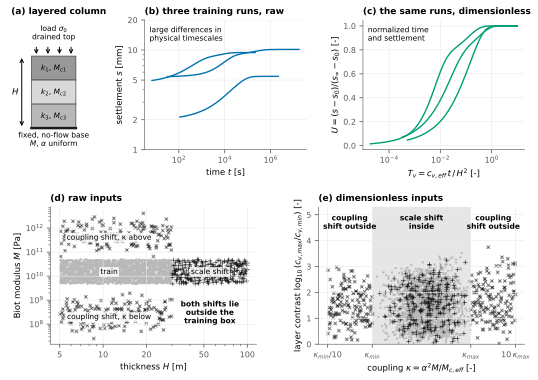

In [6]:
tr, ptr = data["train"], physics(data["train"])
Tc = ptr["H"] ** 2 / ptr["cv_eff"]                    # consolidation time
runs = [int(np.abs(Tc - np.quantile(Tc, q)).argmin()) for q in (.1, .5, .9)]
fig = plt.figure(figsize=(7.5, 5.3))
top = fig.add_gridspec(1, 3, width_ratios=[1, 2, 2], left=0.01, right=0.97,
                       top=0.94, bottom=0.6, wspace=0.42)
low = fig.add_gridspec(1, 2, left=0.09, right=0.97, top=0.45, bottom=0.09,
                       wspace=0.3)
ax = [fig.add_subplot(g) for g in (top[0], top[1], top[2], low[0], low[1])]

a = ax[0]; a.set_axis_off(); a.set(xlim=(0, 1), ylim=(-0.3, 1.5))
for j, grey in enumerate(("0.6", "0.85", "0.72")):       # layers 1-3
    y0 = 1 - (j + 1) / 3
    a.add_patch(Rectangle((0.3, y0), 0.55, 1 / 3, fc=grey, ec="0.2", lw=.6))
    note(a, 0.575, y0 + 1 / 6, f"$k_{j+1}$, $M_{{c{j+1}}}$")
for x in np.linspace(0.36, 0.79, 4):
    a.annotate("", (x, 1.0), (x, 1.15), arrowprops=dict(arrowstyle="->"))
note(a, 0.575, 1.32, "load $\\sigma_0$\ndrained top")
a.plot([0.3, 0.85], [0, 0], color="0.1", lw=2.5)
note(a, 0.575, -0.16, "fixed, no-flow base\n$M$, $\\alpha$ uniform")
a.annotate("", (0.18, 0), (0.18, 1), arrowprops=dict(arrowstyle="<->"))
note(a, 0.1, 0.5, "$H$", fontsize=8.5)
a.set_title("(a) layered column", x=0.05)

X, U, _ = represent(tr.loc[runs], "dimensionless")
for i, tv, u in zip(runs, 10 ** X[:, 0].reshape(3, N_T), U.reshape(3, N_T)):
    ax[1].loglog(tr.loc[i, TIMES], 1e3 * tr.loc[i, SETTLE], c=COLOR["raw"])
    ax[2].semilogx(tv, u, color=COLOR["dimensionless"])
plain_log(ax[1].yaxis, [1, 2, 5, 10, 20])
ax[1].set(xlabel="time $t$ [s]", ylabel="settlement $s$ [mm]",
          title="(b) three training runs, raw")
ax[2].set(xlabel="$T_v = c_{v,eff}\\,t\\,/\\,H^2$ [-]",
          ylabel="$U = (s - s_0)/(s_\\infty - s_0)$ [-]",
          title="(c) the same runs, dimensionless")
note(ax[1], 0.03, 0.95, "large differences in\nphysical timescales",
     ha="left", va="top", transform=ax[1].transAxes)
note(ax[2], 0.03, 0.95, "normalized time\nand settlement", ha="left", va="top",
     transform=ax[2].transAxes)

look = {"train": dict(color="0.72", marker=".", s=6),
        "scale shift": dict(color="0.1", marker="+", s=14, lw=0.6),
        "coupling shift": dict(color="0.1", marker="x", s=10, lw=0.6)}
H, M = tr["H_m"], tr["M_Pa"]
ax[3].add_patch(Rectangle((H.min(), M.min()), H.max() - H.min(),
                          M.max() - M.min(), **BAND))
ax[4].axvspan(K_MIN, K_MAX, **BAND)
for split, kw in look.items():
    df, p = data[split], physics(data[split])
    contrast = np.log10(p["cv"].max(1) / p["cv"].min(1))
    ax[3].scatter(df["H_m"], df["M_Pa"], rasterized=True, **kw)
    ax[4].scatter(p["kappa"], contrast, rasterized=True, **kw)
ax[3].set(xscale="log", yscale="log", xlabel="thickness $H$ [m]",
          ylabel="Biot modulus $M$ [Pa]", title="(d) raw inputs")
plain_log(ax[3].xaxis, [5, 10, 20, 50, 100])
for x, y, s in ((11, 4e11, "coupling shift, κ above"),
                (55, 1.5e10, "scale shift"),
                (11, 2e8, "coupling shift, κ below"), (11, 1.5e10, "train")):
    note(ax[3], x, y, s, box=True)
note(ax[3], 55, 3e8, "both shifts lie\noutside the\ntraining box",
     fontweight="bold")
ax[4].set_xscale("log")
plain_log(ax[4].xaxis, [K_MIN / 10, K_MIN, K_MAX, 10 * K_MAX],
          ["$\\kappa_{min}/10$", "$\\kappa_{min}$", "$\\kappa_{max}$",
           "$10\\,\\kappa_{max}$"])
ax[4].minorticks_off()
ax[4].set(ylim=(0, 5.3), title="(e) dimensionless inputs",
          xlabel="coupling $\\kappa = \\alpha^2 M / M_{c,eff}$ [-]",
          ylabel="layer contrast $\\log_{10}(c_{v,max}/c_{v,min})$ [-]")
note(ax[4], np.sqrt(K_MIN * K_MAX), 4.7, "scale shift\ninside",
     fontweight="bold")
for x in (K_MIN / 3.2, K_MAX * 3.2):
    note(ax[4], x, 4.7, "coupling\nshift outside", fontweight="bold")
plt.show()

* raw timescales (b) differ by decades; in dimensionless form (c) time and settlement are normalized, and the remaining differences reflect layering and coupling, which a model must learn
* in raw inputs (d) both shifts are extrapolation: the scale shift in thickness (and load, permeability), the coupling shift in the Biot modulus
* in dimensionless inputs (e) the scale shift lies inside the training data; the coupling shift stays outside, mainly in κ (changing M also moves the cv ratios or Tv slightly out of range in 3 of 300 simulations)

### 2. Three Representations of the Same Data

A **feature** is an input supplied to a model and the **target** is the quantity it learns to predict; **feature transformation** changes how the same information is presented ([e-book: Feature Transformations](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_feature_transformations.html)). Here inputs and target change together:

| representation | inputs | target | back to settlement |
|---|---|---|---|
| raw | H, σ0, M, α, k1-3, Mc1-3, t (11) | s [m] | identity |
| log | log10 of each (α linear), log10 t (11) | log10 s | 10^y |
| dimensionless | log Tv, log cv,j/cv,eff, log Mc,j/Mc,eff, α, log κ (9) | U = (s − s0)/(s∞ − s0) | s0 + U (s∞ − s0) |

* each simulation becomes 41 rows, one per sampled time, with the time (t, log10 t or log10 Tv) as an input; the 41 predictions form the history that is scored
* dimensional analysis (Buckingham π): the equations depend only on a few dimensionless groups, so H and σ0 drop out exactly (σ0 by linearity, H into Tv)
* s0 and s∞ follow from a formula, but the path between them does not: how fast each layer drains depends on the layering and coupling and needs the simulator; the dimensionless model predicts this progress U, converted back to settlement with s0 and s∞. The dimensionless approach combines physics-based input features with a target normalized by the analytical settlement limits; this study evaluates their combined benefit.

### 3. Validation Design: Grouped Cross-Validation and Leakage

**Metric:** for simulation $i$, the worst error over its 41 times relative to the delayed settlement, $e_i = \max_t |\hat s_i(t) - s_i(t)| \,/\, (s_{\infty,i} - s_{0,i})$; e.g. s0 = 2 mm, s∞ = 10 mm and a worst error of 0.4 mm give $e$ = 0.4/8 = 5%. After calculating one worst error for each simulation, I report the 95th percentile (P95): about 95% of simulations have errors at or below this value; lower is better.
* the largest error across the 41 sampled times measures how badly the predicted history deviates at its least accurate sampled point; error relative to the total settlement s∞ is a secondary column
* a small delayed settlement makes the normalized error large for a given absolute error (below the κ range s∞ − s0 is only 1-11% of s∞); this denominator applies to every model
* two physical checks, both relative to s∞ − s0; a history fails if at least one sampled prediction violates the criterion: non-monotone if the settlement decreases between adjacent times by more than 0.1%; out of bounds if a prediction lies outside [s0, s∞] by more than 1%

**Cross-validation** repeatedly trains on part of the training data and evaluates on the rest. **Data leakage:** information from the validation data reaches the training data ([e-book: Training and Tuning](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_training_tuning.html)). Rows of one simulation (neighbouring times) are nearly identical, so random-row K-fold puts near-copies of each validation row into training; **grouped K-fold** keeps all time points of one simulation in the same fold ([glossary: groups](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_glossary_a_c.html)). The neural network's (multilayer perceptron, MLP) built-in `early_stopping` also holds out random rows, so it is off.

**Question:** does random-row K-fold tell us how well a model predicts a new simulation? (random forest, raw inputs, the fixed baseline settings described above, 800 training simulations)

In [7]:
tune = data["train"].iloc[:800]                       # simulations for CV
folds = {"random-row K-fold": KFold(3, shuffle=True, random_state=SEED),
         "grouped K-fold": GroupKFold(3)}
leak = {k: scores(tune, cv_predict("random forest", {}, tune, "raw", cv))
        ["P95"] for k, cv in folds.items()}
X, y, _ = represent(tune, "raw")
X_test, _, to_s = represent(data["test"], "raw")
s_test = to_s(make_model("random forest").fit(X, y).predict(X_test))
leak["held-out test"] = scores(data["test"], s_test)["P95"]
print("P95 worst error [% of s∞ − s0]: "
      + ", ".join(f"{k} {v:.0f}%" for k, v in leak.items()))

P95 worst error [% of s∞ − s0]: random-row K-fold 40%, grouped K-fold 270%, held-out test 201%


* random-row K-fold reports 40% against a held-out test error of 201%, underestimating it by about a factor of five, because the forest interpolates between neighbouring times of a simulation that is also represented in the training fold
* grouped K-fold reports 270%; its smaller training sets (two thirds of the 800 simulations per fold) may contribute to the higher error
* the main raw forest (2,000 simulations, min_samples_leaf = 5 chosen by CV, against 800 and 1 here) scores 153% on test

### 4. Model Tuning and Prediction Results

A **hyperparameter** is a model or training setting chosen before fitting; here each is chosen on validation folds, never on test or out-of-range data ([e-book: Training and Tuning](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_training_tuning.html)):
* 3-fold grouped K-fold on 800 training simulations, then the chosen setting is refitted on all 2000; grids fixed before any result was seen: random forest (100 trees) min_samples_leaf ∈ {1, 5}; MLP (64, 64 ReLU units) L2 penalty (weight shrinkage) α ∈ {1e-4, 1e-2} x stopping tolerance ∈ {1e-4, 1e-5}; linear regression has none
* selection uses the reported metric (P95 worst error) on out-of-fold predictions, because the mean squared errors of s, log s and U are on different scales

**Question:** under distribution shift, which matters more, the input representation or the model? (all 9 combinations, refitted on 2000 simulations)

selected MLPs, iterations used of max_iter=500: raw 146, log 44, dimensionless 39


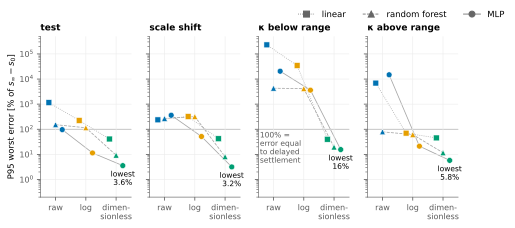

In [8]:
rows, fitted = [], {}
for kind in KINDS:
    X, y, _ = represent(data["train"], kind)
    for name, grid in GRIDS.items():
        with warnings.catch_warnings():        # CV fits only; final fits warn
            warnings.simplefilter("ignore", ConvergenceWarning)
            cv = [scores(tune, cv_predict(name, hp, tune, kind, GroupKFold(3)))
                  ["P95"] for hp in grid]
        hp = grid[int(np.argmin(cv))]
        rows.append({"representation": kind, "model": name, "CV": min(cv),
                     "chosen": " ".join(f"{k}={v:g}" for k, v in hp.items())
                     or "-"})
        fitted[kind, name] = make_model(name, **hp).fit(X, y)
tuning = pd.DataFrame(rows).set_index(["representation", "model"])
print("selected MLPs, iterations used of max_iter=500: " + ", ".join(
    f"{k} {fitted[k, 'MLP'].regressor_[-1].n_iter_}" for k in KINDS))

pred, res = {}, {}
for (kind, name), model in fitted.items():
    for split in EVAL:
        X, _, to_s = represent(data[split], kind)
        pred[kind, name, split] = p = to_s(model.predict(X))
        res[kind, name, split] = scores(data[split], p)

fig, axes = plt.subplots(1, 4, figsize=(7.5, 2.9), sharey=True)
shift = dict(zip(GRIDS, (-0.22, 0.0, 0.22)))
for ax, split in zip(axes, EVAL):
    ax.axhline(100, color="0.45", lw=0.7, zorder=1)
    for name in GRIDS:
        x = [i + shift[name] for i in range(3)]
        v = [res[k, name, split]["P95"] for k in KINDS]
        ax.plot(x, v, color="0.65", lw=0.8, ls=MODEL[name]["ls"], zorder=1)
        ax.scatter(x, v, c=[COLOR[k] for k in KINDS], s=34, zorder=2,
                   marker=MODEL[name]["marker"], edgecolors="white", lw=0.5)
    k, n = min(fitted, key=lambda kn: res[kn[0], kn[1], split]["P95"])
    v = res[k, n, split]["P95"]
    note(ax, KINDS.index(k) + shift[n], v / 1.6, f"lowest\n{v:.2g}%",
         va="top")
    ax.set_xticks(range(3), ["raw", "log", "dimen-\nsionless"])
    ax.set(xlim=(-0.5, 2.5), yscale="log", ylim=(0.2, 5e5), title=split)
axes[0].set_ylabel("P95 worst error [% of $s_\\infty - s_0$]")
note(axes[2], -0.45, 80, "100% =\nerror equal\nto delayed\nsettlement",
     ha="left", va="top", color="0.35")
handles = [plt.Line2D([], [], color="0.4", lw=0.8, **MODEL[n]) for n in GRIDS]
fig.legend(handles, list(GRIDS), loc="upper right", ncol=3, frameon=False,
           bbox_to_anchor=(1, 1.04))                 # model key, once
plt.show()

* the dimensionless representation substantially improved performance in these comparisons, and the dimensionless MLP achieved the lowest errors on all four evaluation sets (3.6%, 3.2%, 15.6%, 5.8%); even in range, the lowest-error raw model (MLP, 97%) is worse than every dimensionless model
* raw and log models fail on the scale shift (52-362%); below the κ range the dimensionless MLP's P95 score is 15.6% when normalized by delayed settlement and 0.6% when normalized by total final settlement
* the selected MLPs stopped by their tolerance rule after 146 (raw), 44 (log) and 39 (dimensionless) of 500 allowed iterations, with no convergence warning

### 5. Why: How Each Model Extrapolates

**Inductive bias** is the set of assumptions imposed by a model's structure, which shape its predictions where it has no data ([e-book: Linear Regression](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_linear_regression.html), [Decision Tree](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_decision_tree.html), [Ensemble Trees](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_ensemble_trees.html), [Artificial Neural Networks](https://geostatsguy.github.io/MachineLearningDemos_Book/MachineLearning_ANN.html)):
* linear regression: one global plane, so it extrapolates linearly
* trees and forests: piecewise constant, so a prediction never leaves the range of the training targets
* ReLU neural network: piecewise linear in its input coordinates, but its behaviour outside the training region is not constrained to follow the physical response
* linearity refers to the chosen coordinates: a model linear in log inputs is not linear in the physical quantities

(a, b) scale shift: raw forest and MLP vs dimensionless forest; (c) coupling shift: the CV-selected model of each representation vs distance beyond the κ limit (dots: individual simulations; lines: rolling medians of 31)

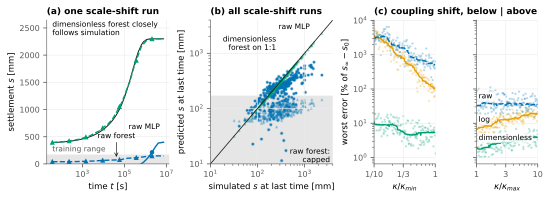

In [9]:
SHOW = {("raw", "random forest"): "raw forest", ("raw", "MLP"): "raw MLP",
        ("dimensionless", "random forest"): "dimensionless forest"}
sc = data["scale shift"]; s_sc = 1e3 * sc[SETTLE].to_numpy()
s_top = 1e3 * tr[SETTLE].to_numpy().max()            # training maximum [mm]
case = int(s_sc[:, -1].argmax())                     # largest scaled run
fig = plt.figure(figsize=(7.5, 2.9))
gs = fig.add_gridspec(1, 4, width_ratios=[1.1, 1.1, 0.55, 0.55], left=0.08,
                      right=0.99, top=0.86, bottom=0.17, wspace=0.45)
a, b, c1 = (fig.add_subplot(gs[i]) for i in range(3))
c2 = fig.add_subplot(gs[3], sharey=c1)
t = sc.loc[case, TIMES].to_numpy(float)
a.axhspan(0, s_top, **BAND); b.axhspan(1, s_top, **BAND)
a.semilogx(t, s_sc[case], color="0.1", lw=1)
for (kind, name), label in SHOW.items():
    st = dict(color=COLOR[kind], marker=MODEL[name]["marker"])
    s_hat = 1e3 * pred[kind, name, "scale shift"].reshape(-1, N_T)
    a.semilogx(t, s_hat[case], ls=MODEL[name]["ls"], ms=3.5, markevery=6,
               **st)
    if (kind, name) == ("raw", "MLP"):
        note(a, t[-1] / 1.5, s_hat[case, -1] + 280, label, ha="right")
    elif kind == "raw":                         # label in free space, arrow
        i = np.searchsorted(t, 3e4)
        a.annotate("", (t[i], s_hat[case, i] + 20), (t[i], s_top + 260),
                   arrowprops=dict(arrowstyle="->", lw=0.6))
        note(a, t[i], s_top + 340, label)
    b.scatter(s_sc[:, -1], s_hat[:, -1], s=8, lw=0, rasterized=True,
              alpha=0.9 if kind == "raw" and name == "MLP" else 0.45, **st)
a.set(ylim=(0, 1.15 * s_sc[case].max()), xlabel="time $t$ [s]",
      ylabel="settlement $s$ [mm]", title="(a) one scale-shift run")
note(a, t[0], 1.08 * s_sc[case].max(),
     "dimensionless forest closely\nfollows simulation", ha="left")
note(a, t[0], s_top + 30, "training range", ha="left", va="bottom",
     color="0.35")
lim = (10, 4000)
b.plot(lim, lim, color="0.1", lw=0.8)
b.set(xscale="log", yscale="log", xlim=lim, ylim=lim,
      xlabel="simulated $s$ at last time [mm]",
      ylabel="predicted $s$ at last time [mm]",
      title="(b) all scale-shift runs")
note(b, 250, 1500, "dimensionless\nforest on 1:1", ha="right")
note(b, 3500, 14, "raw forest:\ncapped", ha="right")
note(b, 1300, 3000, "raw MLP", ha="right")

best_of = tuning.reset_index().loc[
    tuning.reset_index().groupby("representation")["CV"].idxmin()]
for ax, split, limit in ((c1, "κ below range", K_MIN),
                         (c2, "κ above range", K_MAX)):
    ratio = physics(data[split])["kappa"] / limit
    order = np.argsort(ratio)
    for kind, name in zip(best_of.representation, best_of.model):
        err = 100 * worst_error(data[split], pred[kind, name, split])[0]
        ax.scatter(ratio, err, s=4, lw=0, color=COLOR[kind], alpha=0.35,
                   rasterized=True)
        med = pd.Series(err[order]).rolling(31, center=True, min_periods=10)
        med = med.median().to_numpy()
        ax.plot(ratio[order], med, color=COLOR[kind], ls=MODEL[name]["ls"])
        if ax is c2:
            note(ax, 1.08, 1.9 * med[0], kind, ha="left", box=True)
    ax.set(xscale="log", yscale="log")
plain_log(c1.xaxis, [0.1, 0.3, 1], ["1/10", "1/3", "1"])
plain_log(c2.xaxis, [1, 3, 10])
c1.set(xlim=(0.1, 1), xlabel="$\\kappa/\\kappa_{min}$",
       ylabel="worst error [% of $s_\\infty - s_0$]")
c2.set(xlim=(1, 10), xlabel="$\\kappa/\\kappa_{max}$")
c2.tick_params(labelleft=False)
c1.set_title("(c) coupling shift, below | above")
plt.show()

* (a, b) the raw-input forest never predicts more than 147 mm, inside the training range (at most 172 mm), while scale-shift runs settle up to 2.3 m; the raw MLP's scale-shift predictions depart substantially from the simulated response
* the dimensionless forest closely follows the simulation: it predicts U, and s0 and s∞ restore the physical scale; this works on the scale shift because, in dimensionless form, those cases resemble the training data. A bounded target does not by itself make extrapolation harmless: the forest can still predict the wrong U
* (c) raw and log errors grow with distance below the κ range; dimensionless errors stay near 5-10% below and grow slowly above (median 2% at the limit, 4% at 10x)

### Results

All 9 combinations: P95 worst error in % of s∞ − s0 unless noted; checks = % of the 600 out-of-range simulations that fail.

In [10]:
n = np.array([len(data[s]) for s in EVAL[1:]])
ood = lambda key, c: n @ [res[key + (s,)][c] for s in EVAL[1:]] / n.sum()
table = tuning[["chosen", "CV"]].assign(
    **{s: [res[key + (s,)]["P95"] for key in tuning.index] for s in EVAL},
    **{"κ below range, % of s∞": [res[key + ("κ below range",)]
                                  ["P95 of s_inf"] for key in tuning.index]},
    **{f"{c} [%]": [ood(key, c) for key in tuning.index]
       for c in ("non-monotone", "out of bounds")})
table.round(1)

chosen      CV    test  \
representation model                                                 
raw            linear                            -  1367.8  1152.0   
               random forest    min_samples_leaf=5   250.3   152.6   
               MLP            alpha=0.01 tol=1e-05   313.9    96.9   
log            linear                            -   237.2   224.7   
               random forest    min_samples_leaf=5   178.8   115.0   
               MLP            alpha=0.01 tol=1e-05    24.4    11.4   
dimensionless  linear                            -    40.1    41.1   
               random forest    min_samples_leaf=1    12.6     9.3   
               MLP            alpha=0.01 tol=1e-05     4.1     3.6   

                              scale shift  κ below range  κ above range  \
representation model                                                      
raw            linear               237.7       229528.3         6897.0   
               random forest        269.8         4309.3           79.2   
               MLP                  361.8        20460.2        14784.4   
log            linear               322.8        34418.6           70.2   
               random forest        321.2         4159.5           61.6   
               MLP                   51.7         3614.8           21.2   
dimensionless  linear                42.0           40.2           45.4   
               random forest          8.1           19.6           11.7   
               MLP                    3.2           15.6            5.8   

                              κ below range, % of s∞  non-monotone [%]  \
representation model                                                     
raw            linear                         5402.8               0.0   
               random forest                    76.4              44.8   
               MLP                             334.6              28.5   
log            linear                          399.1               0.0   
               random forest                    63.3              52.5   
               MLP                              43.8              48.2   
dimensionless  linear                            2.0               0.0   
               random forest                     1.1               2.5   
               MLP                               0.6              11.3   

                              out of bounds [%]  
representation model                             
raw            linear                      80.8  
               random forest               89.3  
               MLP                         89.0  
log            linear                      62.8  
               random forest               87.2  
               MLP                         64.5  
dimensionless  linear                      96.8  
               random forest                0.0  
               MLP                         17.8

* for these representations, models and test sets: yes for the scale shift, which dimensionless inputs and target made a familiar problem; partly for the coupling shift, which still raised the best model's error 1.6-4.3-fold
* representation determines where a case lies relative to the training data; model assumptions influence predictions outside that region
* out of bounds (share of out-of-range simulations with at least one predicted time outside the bounds): 0% for the dimensionless forest, 18% for the dimensionless MLP; a bounded output would fix this but not monotonicity (non-monotone 2.5% and 11.3%)

### Parting Comments / Promote You

* nondimensionalise inputs and target before fitting when the governing equations are known; group cross-validation folds by simulation, experiment or well; check where a new case sits in the model's input space before trusting it
* limitations: one physics problem, small hyperparameter grids, one seed per model, P95 over 150-300 simulations per split
* I am a PhD student in Petroleum and Geosystems Engineering at UT Austin, working on coupled flow and geomechanics with fully coupled simulations in the OpenFOAM framework, especially on parent-child well fracture interactions

### Attribution

* methods and concepts follow the course e-book, cited by chapter where they are used: Pyrcz, M.J., *Applied Machine Learning in Python: a Hands-on Guide with Code* (CC BY-NC-ND 4.0); no code was copied from it
* models and cross-validation: scikit-learn
* simulator and data: a layered extension of the reference solver in [poroConsolidationFoam](https://github.com/nakulsanadhya/poroConsolidationFoam)
* Claude (Anthropic) assisted with drafting the notebook code, figures and text, and the layered solver and data-generation code.

I hope this was helpful,

*Nakul*